In [19]:
!pip -q install sentence-transformers pandas numpy scikit-learn matplotlib seaborn

In [20]:
import pandas as pd
import numpy as np
import random
import json
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

from IPython.display import display

In [21]:
print("Loading NLP model...")

model = SentenceTransformer("all-MiniLM-L6-v2")

print("NLP model loaded successfully!")

Loading NLP model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

NLP model loaded successfully!


In [22]:
questions = [

    # -------------------------
    # OVERFITTING
    # -------------------------

    {
        "id": 1,
        "concept": "Overfitting",
        "difficulty": "Easy",
        "question": "What is overfitting in machine learning?",
        "answer": "Overfitting occurs when a model learns the training data too closely, including noise, and performs poorly on unseen data."
    },

    {
        "id": 2,
        "concept": "Overfitting",
        "difficulty": "Medium",
        "question": "Why does overfitting cause poor performance on test data?",
        "answer": "Overfitting causes poor test performance because the model learns specific patterns and noise from the training data instead of general patterns."
    },

    {
        "id": 3,
        "concept": "Overfitting",
        "difficulty": "Hard",
        "question": "How can regularization help prevent overfitting?",
        "answer": "Regularization adds a penalty for model complexity, encouraging simpler models that generalize better to unseen data."
    },


    # -------------------------
    # CLASSIFICATION
    # -------------------------

    {
        "id": 4,
        "concept": "Classification",
        "difficulty": "Easy",
        "question": "What is classification in machine learning?",
        "answer": "Classification is a supervised learning task in which a model predicts discrete categories or classes."
    },

    {
        "id": 5,
        "concept": "Classification",
        "difficulty": "Medium",
        "question": "What is the difference between binary and multiclass classification?",
        "answer": "Binary classification predicts one of two classes, while multiclass classification predicts one of more than two classes."
    },

    {
        "id": 6,
        "concept": "Classification",
        "difficulty": "Hard",
        "question": "How does logistic regression perform classification?",
        "answer": "Logistic regression calculates a probability using the logistic function and assigns the input to a class using a decision threshold."
    },


    # -------------------------
    # REGRESSION
    # -------------------------

    {
        "id": 7,
        "concept": "Regression",
        "difficulty": "Easy",
        "question": "What is regression in machine learning?",
        "answer": "Regression is a supervised learning technique used to predict continuous numerical values."
    },

    {
        "id": 8,
        "concept": "Regression",
        "difficulty": "Medium",
        "question": "What is the purpose of a regression model?",
        "answer": "A regression model learns relationships between variables and predicts a continuous target value."
    },

    {
        "id": 9,
        "concept": "Regression",
        "difficulty": "Hard",
        "question": "What is the difference between MAE and RMSE?",
        "answer": "MAE measures the average absolute error, while RMSE is the square root of mean squared error and gives greater importance to large errors."
    },


    # -------------------------
    # CROSS VALIDATION
    # -------------------------

    {
        "id": 10,
        "concept": "Cross Validation",
        "difficulty": "Easy",
        "question": "What is cross-validation?",
        "answer": "Cross-validation is a technique used to evaluate a machine learning model using multiple training and validation splits."
    },

    {
        "id": 11,
        "concept": "Cross Validation",
        "difficulty": "Medium",
        "question": "Why is k-fold cross-validation useful?",
        "answer": "K-fold cross-validation provides a more reliable estimate of model performance by training and validating the model on different subsets of the data."
    },

    {
        "id": 12,
        "concept": "Cross Validation",
        "difficulty": "Hard",
        "question": "How does k-fold cross-validation work?",
        "answer": "The dataset is divided into k subsets, and the model is trained k times using one subset for validation and the remaining subsets for training."
    },


    # -------------------------
    # UNDERFITTING
    # -------------------------

    {
        "id": 13,
        "concept": "Underfitting",
        "difficulty": "Easy",
        "question": "What is underfitting?",
        "answer": "Underfitting occurs when a model is too simple to learn the important patterns in the training data."
    },

    {
        "id": 14,
        "concept": "Underfitting",
        "difficulty": "Medium",
        "question": "What are common causes of underfitting?",
        "answer": "Underfitting can occur when the model is too simple, the features are insufficient, or the model is not trained adequately."
    },

    {
        "id": 15,
        "concept": "Underfitting",
        "difficulty": "Hard",
        "question": "How can underfitting be reduced?",
        "answer": "Underfitting can be reduced by using a more complex model, improving features, reducing excessive regularization, or training the model longer."
    },


    # -------------------------
    # KNN
    # -------------------------

    {
        "id": 16,
        "concept": "KNN",
        "difficulty": "Easy",
        "question": "What is KNN?",
        "answer": "K-nearest neighbors is a supervised learning algorithm that predicts a value or class using the nearest training examples."
    },

    {
        "id": 17,
        "concept": "KNN",
        "difficulty": "Medium",
        "question": "How does KNN classify a new data point?",
        "answer": "KNN finds the k nearest training examples and assigns the class that is most common among those neighbors."
    },

    {
        "id": 18,
        "concept": "KNN",
        "difficulty": "Hard",
        "question": "How does the value of k affect KNN?",
        "answer": "A small k can make KNN sensitive to noise, while a large k produces smoother predictions but may ignore local patterns."
    }
]

question_df = pd.DataFrame(questions)

print("Question bank created successfully!")
print(f"Total questions: {len(question_df)}")

display(question_df.head())

Question bank created successfully!
Total questions: 18


,id,concept,difficulty,question,answer
0,1,Overfitting,Easy,What is overfitting in machine learning?,Overfitting occurs when a model learns the tra...
1,2,Overfitting,Medium,Why does overfitting cause poor performance on...,Overfitting causes poor test performance becau...
2,3,Overfitting,Hard,How can regularization help prevent overfitting?,Regularization adds a penalty for model comple...
3,4,Classification,Easy,What is classification in machine learning?,Classification is a supervised learning task i...
4,5,Classification,Medium,What is the difference between binary and mult...,Binary classification predicts one of two clas...


In [23]:
print("Concepts available:")

for concept in question_df["concept"].unique():
    count = len(question_df[question_df["concept"] == concept])
    print(f"- {concept}: {count} questions")

Concepts available:
- Overfitting: 3 questions
- Classification: 3 questions
- Regression: 3 questions
- Cross Validation: 3 questions
- Underfitting: 3 questions
- KNN: 3 questions


In [24]:
concepts = question_df["concept"].unique()

student_profile = {}

for concept in concepts:
    student_profile[concept] = {
        "mastery": 50.0,
        "attempts": 0,
        "correct": 0,
        "incorrect": 0,
        "partial": 0
    }

student_profile

{'Overfitting': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Classification': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Regression': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Cross Validation': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Underfitting': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'KNN': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0}}

In [25]:
concepts = question_df["concept"].unique()

student_profile = {}

for concept in concepts:
    student_profile[concept] = {
        "mastery": 50.0,
        "attempts": 0,
        "correct": 0,
        "incorrect": 0,
        "partial": 0
    }

student_profile

{'Overfitting': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Classification': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Regression': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Cross Validation': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'Underfitting': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0},
 'KNN': {'mastery': 50.0,
  'attempts': 0,
  'correct': 0,
  'incorrect': 0,
  'partial': 0}}

In [26]:
def evaluate_answer(student_answer, correct_answer):

    student_embedding = model.encode(
        [student_answer],
        convert_to_numpy=True
    )

    correct_embedding = model.encode(
        [correct_answer],
        convert_to_numpy=True
    )

    similarity = cosine_similarity(
        student_embedding,
        correct_embedding
    )[0][0]

    score = float(similarity * 100)

    return round(score, 2)

In [27]:
def classify_answer(score):

    if score >= 70:
        return "Correct"

    elif score >= 45:
        return "Partially Correct"

    else:
        return "Incorrect"

In [9]:
def choose_difficulty(concept):

    score = mastery[concept]

    if score < 40:
        return "Easy"

    elif score < 70:
        return "Medium"

    else:
        return "Hard"

In [28]:
correct_answer = (
    "Overfitting occurs when a model learns the training data "
    "too closely and performs poorly on unseen data."
)

student_answer = (
    "The model memorizes the training examples and "
    "does not generalize well to new data."
)

score = evaluate_answer(
    student_answer,
    correct_answer
)

evaluation = classify_answer(score)

print(f"Semantic Similarity: {score}%")
print(f"Evaluation: {evaluation}")

Semantic Similarity: 49.94%
Evaluation: Partially Correct


In [29]:
def update_student_model(concept, evaluation):

    profile = student_profile[concept]

    # Increase attempt count
    profile["attempts"] += 1

    # Update based on answer quality
    if evaluation == "Correct":
        profile["correct"] += 1
        profile["mastery"] += 10

    elif evaluation == "Partially Correct":
        profile["partial"] += 1
        profile["mastery"] += 3

    else:
        profile["incorrect"] += 1
        profile["mastery"] -= 10

    # Keep mastery between 0 and 100
    profile["mastery"] = max(
        0,
        min(100, profile["mastery"])
    )

    return round(profile["mastery"], 2)

In [30]:
def get_weak_concepts():

    weak_concepts = []

    for concept, profile in student_profile.items():

        if profile["mastery"] < 60:
            weak_concepts.append(
                (concept, profile["mastery"])
            )

    weak_concepts.sort(
        key=lambda x: x[1]
    )

    return weak_concepts

    print("Weak concepts:")

for concept, mastery_score in get_weak_concepts():
    print(f"{concept}: {mastery_score}%")

Overfitting: 50.0%
Classification: 50.0%
Regression: 50.0%
Cross Validation: 50.0%
Underfitting: 50.0%
KNN: 50.0%


In [31]:
def determine_difficulty(concept):

    mastery_score = student_profile[concept]["mastery"]

    if mastery_score < 40:
        return "Easy"

    elif mastery_score < 70:
        return "Medium"

    else:
        return "Hard"

In [38]:
def calculate_priority(concept):

    profile = student_profile[concept]

    mastery_score = profile["mastery"]

    attempts = profile["attempts"]

    # Lower mastery = higher priority
    weakness_score = 100 - mastery_score

    # Concepts never attempted get a small exploration bonus
    exploration_bonus = 20 if attempts == 0 else 0

    priority = weakness_score + exploration_bonus

    return priority

for concept in concepts:

    priority = calculate_priority(concept)

    print(
        f"{concept}: Priority = {priority:.2f}"
    )

Overfitting: Priority = 70.00
Classification: Priority = 70.00
Regression: Priority = 70.00
Cross Validation: Priority = 70.00
Underfitting: Priority = 70.00
KNN: Priority = 70.00


In [39]:
def select_target_concept():

    priorities = {}

    for concept in concepts:

        priorities[concept] = calculate_priority(
            concept
        )

    target_concept = max(
        priorities,
        key=priorities.get
    )

    return target_concept

target = select_target_concept()

print("Recommended concept:", target)

Recommended concept: Overfitting


In [40]:
def select_next_question():

    target_concept = select_target_concept()

    difficulty = determine_difficulty(
        target_concept
    )

    candidates = question_df[
        (question_df["concept"] == target_concept) &
        (question_df["difficulty"] == difficulty)
    ]

    # If a question at the required difficulty
    # is unavailable, use another question
    # from the same concept.

    if len(candidates) == 0:

        candidates = question_df[
            question_df["concept"] == target_concept
        ]

    # Avoid repeatedly selecting the same question
    # when possible.

    if "asked" in candidates.columns:

        unanswered = candidates[
            candidates["asked"] == False
        ]

        if len(unanswered) > 0:
            candidates = unanswered

    selected_question = candidates.sample(
        n=1
    ).iloc[0]

    return selected_question

In [41]:
question_df["asked"] = False

question_df["attempts"] = 0

In [42]:
def select_next_question():

    target_concept = select_target_concept()

    difficulty = determine_difficulty(
        target_concept
    )

    candidates = question_df[
        (question_df["concept"] == target_concept) &
        (question_df["difficulty"] == difficulty) &
        (question_df["asked"] == False)
    ]

    # If all questions of that difficulty
    # have already been used, allow repetition.

    if len(candidates) == 0:

        candidates = question_df[
            (question_df["concept"] == target_concept) &
            (question_df["difficulty"] == difficulty)
        ]

    # If still unavailable, use any question
    # from the target concept.

    if len(candidates) == 0:

        candidates = question_df[
            question_df["concept"] == target_concept
        ]

    question = candidates.sample(
        n=1
    ).iloc[0]

    question_df.loc[
        question_df["id"] == question["id"],
        "asked"
    ] = True

    question_df.loc[
        question_df["id"] == question["id"],
        "attempts"
    ] += 1

    return question

In [43]:
progress_history = []

def record_progress(
    question,
    score,
    evaluation
):

    concept = question["concept"]

    progress_history.append({

        "Question ID": question["id"],

        "Concept": concept,

        "Difficulty": question["difficulty"],

        "Score": score,

        "Evaluation": evaluation,

        "Mastery": student_profile[
            concept
        ]["mastery"],

        "Attempts": student_profile[
            concept
        ]["attempts"]
    })

In [57]:
def ask_question():

    question = select_next_question()

    print("\n" + "=" * 60)

    print("ADAPTIVE AI TUTOR")

    print("=" * 60)

    print(
        f"Concept: {question['concept']}"
    )

    print(
        f"Difficulty: {question['difficulty']}"
    )

    print("\nQuestion:")

    print(
        question["question"]
    )

    print("\n" + "-" * 60)

    student_answer = input(
        "Your answer: "
    )

    if student_answer.lower().strip() == "exit":

        return False

    # Evaluate answer
    score = evaluate_answer(
        student_answer,
        question["answer"]
    )

    evaluation = classify_answer(
        score
    )

    # Update cognitive model
    new_mastery = update_student_model(
        question["concept"],
        evaluation
    )

    # Record attempt
    record_progress(
        question,
        score,
        evaluation
    )

    print("\nRESULT")
    print("-" * 60)

    print(
        f"Semantic Score: {score}%"
    )

    print(
        f"Evaluation: {evaluation}"
    )

    print(
        f"{question['concept']} Mastery: "
        f"{new_mastery}%"
    )

    return True

In [53]:
def start_tutoring_session():

    print("=" * 60)
    print("        ADAPTIVE AI TUTOR")
    print("=" * 60)

    print(
        "\nThe tutor will adapt questions "
        "based on your performance."
    )

    print(
        "\nType 'exit' at any time to stop."
    )

    print("=" * 60)

    for i in range(10):

        print(
            f"\n\nQUESTION {i + 1} OF 10"
        )

        result = ask_question()

        if result == False:
            break

    print("\n")
    print("=" * 60)
    print("SESSION COMPLETED")
    print("=" * 60)

start_tutoring_session()

        ADAPTIVE AI TUTOR

The tutor will adapt questions based on your performance.

Type 'exit' at any time to stop.


QUESTION 1 OF 10

ADAPTIVE AI TUTOR
Concept: Overfitting
Difficulty: Medium

Question:
Why does overfitting cause poor performance on test data?

------------------------------------------------------------
Your answer: Because it fails on test data

RESULT
------------------------------------------------------------
Semantic Score: 41.24%
Evaluation: Incorrect
Overfitting Mastery: 40.0%


QUESTION 2 OF 10

ADAPTIVE AI TUTOR
Concept: Classification
Difficulty: Medium

Question:
What is the difference between binary and multiclass classification?

------------------------------------------------------------
Your answer: Binary takes a single class while multiclass takes several classes for classification

RESULT
------------------------------------------------------------
Semantic Score: 79.13%
Evaluation: Correct
Classification Mastery: 60.0%


QUESTION 3 OF 10

ADAP

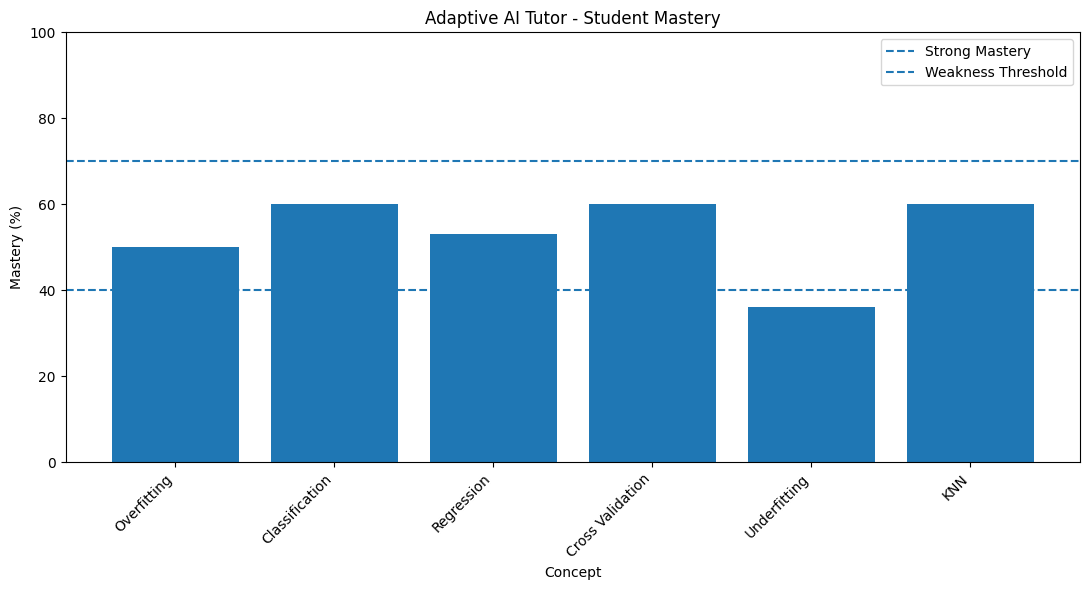

In [58]:
def show_mastery_dashboard():

    concepts_list = []
    mastery_scores = []

    for concept, profile in student_profile.items():

        concepts_list.append(concept)
        mastery_scores.append(
            profile["mastery"]
        )

    plt.figure(figsize=(11, 6))

    plt.bar(
        concepts_list,
        mastery_scores
    )

    plt.axhline(
        y=70,
        linestyle="--",
        label="Strong Mastery"
    )

    plt.axhline(
        y=40,
        linestyle="--",
        label="Weakness Threshold"
    )

    plt.xlabel("Concept")
    plt.ylabel("Mastery (%)")

    plt.title(
        "Adaptive AI Tutor - Student Mastery"
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.ylim(0, 100)

    plt.legend()

    plt.tight_layout()

    plt.show()

show_mastery_dashboard()

In [69]:
def show_progress_table():

    if len(progress_history) == 0:

        print(
            "No tutoring attempts recorded yet."
        )

        return

    progress_df = pd.DataFrame(
        progress_history
    )

    display(progress_df)

show_progress_table()

,Question ID,Concept,Difficulty,Score,Evaluation,Mastery,Attempts
0,2,Overfitting,Medium,41.24,Incorrect,40.0,1
1,5,Classification,Medium,79.13,Correct,60.0,1
2,8,Regression,Medium,69.33,Partially Correct,53.0,1
3,11,Cross Validation,Medium,77.63,Correct,60.0,1
4,14,Underfitting,Medium,34.10,Incorrect,40.0,1
5,17,KNN,Medium,82.50,Correct,60.0,1
6,2,Overfitting,Medium,78.41,Correct,50.0,2
7,14,Underfitting,Medium,59.88,Partially Correct,43.0,2
8,14,Underfitting,Medium,59.70,Partially Correct,46.0,3
9,14,Underfitting,Medium,0.37,Incorrect,36.0,4


In [77]:
def show_weak_concepts():

    weak = get_weak_concepts()

    print("=" * 50)
    print("WEAK CONCEPT ANALYSIS")
    print("=" * 50)

    if len(weak) == 0:

        print(
            "No major weak concepts detected."
        )

        return

    for concept, score in weak:

        print(
            f"{concept}: {score}% mastery"
        )

show_weak_concepts()

WEAK CONCEPT ANALYSIS
Underfitting: 36.0% mastery
Overfitting: 50.0% mastery
Regression: 53.0% mastery


In [80]:
def save_student_progress(filename="student_profile.json"):

    # Convert NumPy numeric values into normal Python values
    clean_profile = {}

    for concept, profile in student_profile.items():

        clean_profile[concept] = {
            "mastery": float(profile["mastery"]),
            "attempts": int(profile["attempts"]),
            "correct": int(profile["correct"]),
            "incorrect": int(profile["incorrect"]),
            "partial": int(profile["partial"])
        }

    # Clean progress history
    clean_history = []

    for record in progress_history:

        clean_record = {}

        for key, value in record.items():

            if isinstance(value, (np.integer,)):
                clean_record[key] = int(value)

            elif isinstance(value, (np.floating,)):
                clean_record[key] = float(value)

            else:
                clean_record[key] = value

        clean_history.append(clean_record)

    # Combine everything
    data = {
        "student_profile": clean_profile,
        "progress_history": clean_history
    }

    # Save as JSON
    with open(filename, "w") as file:

        json.dump(
            data,
            file,
            indent=4
        )

    print(f"Progress saved successfully to: {filename}")

save_student_progress()

Progress saved successfully to: student_profile.json


In [82]:
def load_student_progress(
    filename="student_profile.json"
):

    global student_profile
    global progress_history

    if not os.path.exists(filename):

        print(
            "No saved progress found."
        )

        return

    with open(
        filename,
        "r"
    ) as file:

        data = json.load(file)

    student_profile = data[
        "student_profile"
    ]

    progress_history = data[
        "progress_history"
    ]

    print(
        "Student progress loaded successfully!"
    )

load_student_progress()

Student progress loaded successfully!


In [83]:
def calculate_overall_performance():

    if len(progress_history) == 0:
        print("No attempts recorded yet.")
        return

    scores = [
        float(record["Score"])
        for record in progress_history
    ]

    average_score = np.mean(scores)

    correct = sum(
        1 for record in progress_history
        if record["Evaluation"] == "Correct"
    )

    total = len(progress_history)

    accuracy = (correct / total) * 100

    print("=" * 55)
    print("OVERALL STUDENT PERFORMANCE")
    print("=" * 55)

    print(f"Questions Attempted : {total}")
    print(f"Average NLP Score   : {average_score:.2f}%")
    print(f"Answer Accuracy     : {accuracy:.2f}%")

calculate_overall_performance()

OVERALL STUDENT PERFORMANCE
Questions Attempted : 10
Average NLP Score   : 58.23%
Answer Accuracy     : 40.00%


In [84]:
def show_concept_performance():

    if len(progress_history) == 0:
        print("No attempts recorded yet.")
        return

    df = pd.DataFrame(progress_history)

    concept_summary = df.groupby("Concept").agg(
        Attempts=("Concept", "count"),
        Average_Score=("Score", "mean"),
        Final_Mastery=("Mastery", "last")
    ).reset_index()

    concept_summary["Average_Score"] = (
        concept_summary["Average_Score"].round(2)
    )

    concept_summary["Final_Mastery"] = (
        concept_summary["Final_Mastery"].round(2)
    )

    display(concept_summary)

show_concept_performance()

,Concept,Attempts,Average_Score,Final_Mastery
0,Classification,1,79.13,60.0
1,Cross Validation,1,77.63,60.0
2,KNN,1,82.50,60.0
3,Overfitting,2,59.82,50.0
4,Regression,1,69.33,53.0
5,Underfitting,4,38.51,36.0


,Difficulty,Attempts,Average_Score
0,Medium,10,58.23


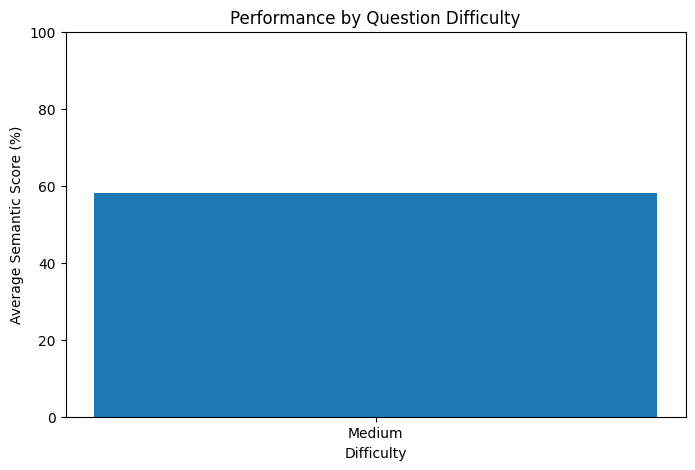

In [85]:
def show_difficulty_analysis():

    if len(progress_history) == 0:
        print("No attempts recorded yet.")
        return

    df = pd.DataFrame(progress_history)

    difficulty_summary = df.groupby(
        "Difficulty"
    ).agg(
        Attempts=("Difficulty", "count"),
        Average_Score=("Score", "mean")
    ).reset_index()

    difficulty_summary["Average_Score"] = (
        difficulty_summary["Average_Score"].round(2)
    )

    display(difficulty_summary)

    plt.figure(figsize=(8, 5))

    plt.bar(
        difficulty_summary["Difficulty"],
        difficulty_summary["Average_Score"]
    )

    plt.xlabel("Difficulty")
    plt.ylabel("Average Semantic Score (%)")
    plt.title("Performance by Question Difficulty")

    plt.ylim(0, 100)

    plt.show()

show_difficulty_analysis()

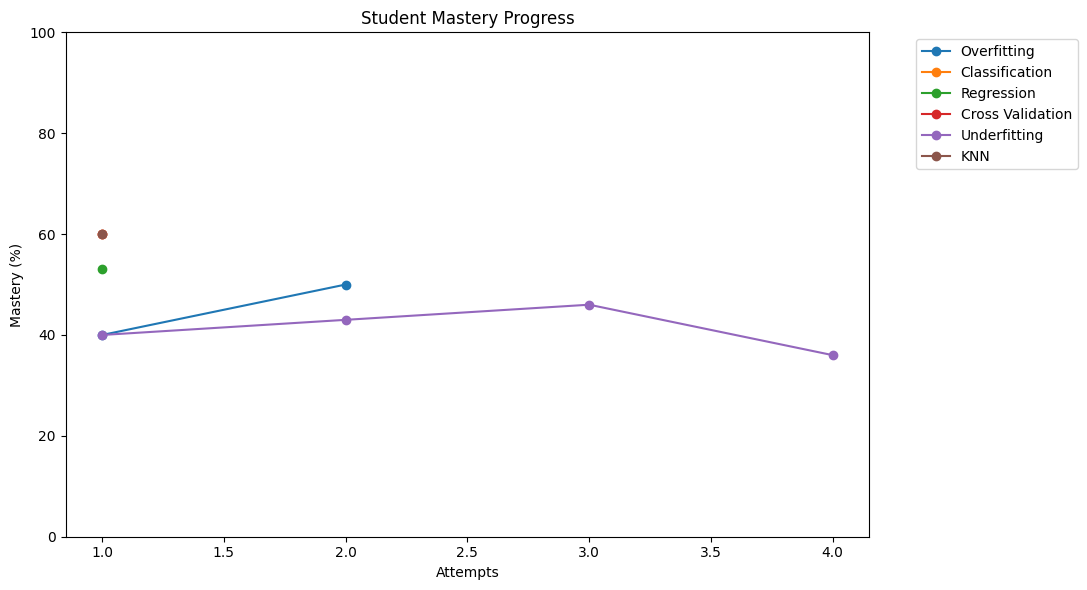

In [86]:
def show_mastery_progress():

    if len(progress_history) == 0:
        print("No progress recorded yet.")
        return

    df = pd.DataFrame(progress_history)

    plt.figure(figsize=(11, 6))

    for concept in df["Concept"].unique():

        concept_data = df[
            df["Concept"] == concept
        ]

        plt.plot(
            range(1, len(concept_data) + 1),
            concept_data["Mastery"],
            marker="o",
            label=concept
        )

    plt.xlabel("Attempts")
    plt.ylabel("Mastery (%)")
    plt.title("Student Mastery Progress")

    plt.ylim(0, 100)

    plt.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

    plt.tight_layout()

    plt.show()

show_mastery_progress()

In [88]:
def generate_final_report():

    print("=" * 65)
    print("              ADAPTIVE AI TUTOR REPORT")
    print("=" * 65)

    if len(progress_history) == 0:

        print("\nNo learning activity recorded.")

        return

    total_attempts = len(progress_history)

    correct_answers = sum(
        1
        for record in progress_history
        if record["Evaluation"] == "Correct"
    )

    partial_answers = sum(
        1
        for record in progress_history
        if record["Evaluation"] == "Partially Correct"
    )

    incorrect_answers = sum(
        1
        for record in progress_history
        if record["Evaluation"] == "Incorrect"
    )

    accuracy = (
        correct_answers /
        total_attempts
    ) * 100

    average_score = np.mean([
        float(record["Score"])
        for record in progress_history
    ])

    print(f"\nTotal Attempts      : {total_attempts}")
    print(f"Correct Answers     : {correct_answers}")
    print(f"Partial Answers     : {partial_answers}")
    print(f"Incorrect Answers   : {incorrect_answers}")
    print(f"Accuracy            : {accuracy:.2f}%")
    print(f"Average NLP Score   : {average_score:.2f}%")

    print("\nCONCEPT MASTERY")
    print("-" * 65)

    for concept, profile in student_profile.items():

        mastery_score = profile["mastery"]

        if mastery_score >= 70:
            status = "Strong"

        elif mastery_score >= 40:
            status = "Developing"

        else:
            status = "Weak"

        print(
            f"{concept:<20} "
            f"{mastery_score:>6.1f}%  "
            f"{status}"
        )

    print("\nRECOMMENDED FOCUS")

    weak = get_weak_concepts()

    if len(weak) == 0:

        print(
            "No major weaknesses detected."
        )

    else:

        for concept, score in weak[:3]:

            print(
                f"- {concept} "
                f"({score:.1f}% mastery)"
            )

    print("\n" + "=" * 65)

generate_final_report()

              ADAPTIVE AI TUTOR REPORT

Total Attempts      : 10
Correct Answers     : 4
Partial Answers     : 3
Incorrect Answers   : 3
Accuracy            : 40.00%
Average NLP Score   : 58.23%

CONCEPT MASTERY
-----------------------------------------------------------------
Overfitting            50.0%  Developing
Classification         60.0%  Developing
Regression             53.0%  Developing
Cross Validation       60.0%  Developing
Underfitting           36.0%  Weak
KNN                    60.0%  Developing

RECOMMENDED FOCUS
- Underfitting (36.0% mastery)
- Overfitting (50.0% mastery)
- Regression (53.0% mastery)



In [89]:
def export_progress():

    if len(progress_history) == 0:

        print("No progress to export.")

        return

    progress_df = pd.DataFrame(
        progress_history
    )

    progress_df.to_csv(
        "adaptive_tutor_progress.csv",
        index=False
    )

    mastery_data = []

    for concept, profile in student_profile.items():

        mastery_data.append({
            "Concept": concept,
            "Mastery": profile["mastery"],
            "Attempts": profile["attempts"],
            "Correct": profile["correct"],
            "Partial": profile["partial"],
            "Incorrect": profile["incorrect"]
        })

    mastery_df = pd.DataFrame(
        mastery_data
    )

    mastery_df.to_csv(
        "concept_mastery.csv",
        index=False
    )

    print("Files exported successfully:")
    print("- adaptive_tutor_progress.csv")
    print("- concept_mastery.csv")

export_progress()

Files exported successfully:
- adaptive_tutor_progress.csv
- concept_mastery.csv


ADAPTIVE AI TUTOR

1. Starting tutoring session...

        ADAPTIVE AI TUTOR

The tutor will adapt questions based on your performance.

Type 'exit' at any time to stop.


QUESTION 1 OF 10

ADAPTIVE AI TUTOR
Concept: Underfitting
Difficulty: Easy

Question:
What is underfitting?

------------------------------------------------------------
Your answer: exit


SESSION COMPLETED

2. Generating mastery dashboard...



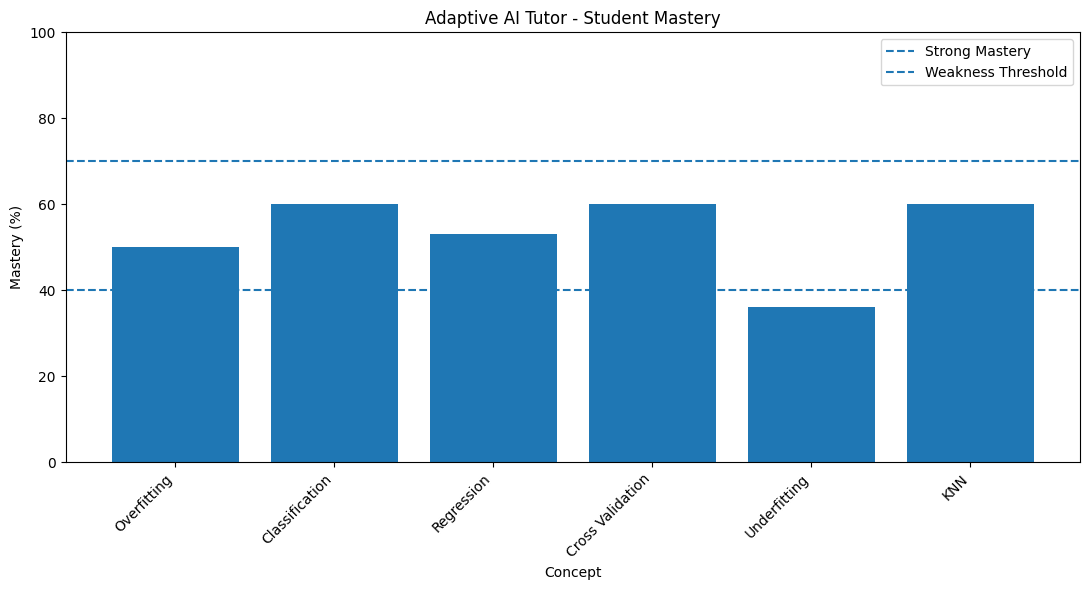


3. Generating progress table...



,Question ID,Concept,Difficulty,Score,Evaluation,Mastery,Attempts
0,2,Overfitting,Medium,41.24,Incorrect,40.0,1
1,5,Classification,Medium,79.13,Correct,60.0,1
2,8,Regression,Medium,69.33,Partially Correct,53.0,1
3,11,Cross Validation,Medium,77.63,Correct,60.0,1
4,14,Underfitting,Medium,34.10,Incorrect,40.0,1
5,17,KNN,Medium,82.50,Correct,60.0,1
6,2,Overfitting,Medium,78.41,Correct,50.0,2
7,14,Underfitting,Medium,59.88,Partially Correct,43.0,2
8,14,Underfitting,Medium,59.70,Partially Correct,46.0,3
9,14,Underfitting,Medium,0.37,Incorrect,36.0,4



4. Generating weak concept analysis...

WEAK CONCEPT ANALYSIS
Underfitting: 36.0% mastery
Overfitting: 50.0% mastery
Regression: 53.0% mastery

5. Generating final report...

              ADAPTIVE AI TUTOR REPORT

Total Attempts      : 10
Correct Answers     : 4
Partial Answers     : 3
Incorrect Answers   : 3
Accuracy            : 40.00%
Average NLP Score   : 58.23%

CONCEPT MASTERY
-----------------------------------------------------------------
Overfitting            50.0%  Developing
Classification         60.0%  Developing
Regression             53.0%  Developing
Cross Validation       60.0%  Developing
Underfitting           36.0%  Weak
KNN                    60.0%  Developing

RECOMMENDED FOCUS
- Underfitting (36.0% mastery)
- Overfitting (50.0% mastery)
- Regression (53.0% mastery)


6. Exporting results...

Files exported successfully:
- adaptive_tutor_progress.csv
- concept_mastery.csv

Adaptive tutoring session completed successfully!


In [90]:
print("ADAPTIVE AI TUTOR")
print("=" * 60)

print("\n1. Starting tutoring session...\n")

start_tutoring_session()

print("\n2. Generating mastery dashboard...\n")

show_mastery_dashboard()

print("\n3. Generating progress table...\n")

show_progress_table()

print("\n4. Generating weak concept analysis...\n")

show_weak_concepts()

print("\n5. Generating final report...\n")

generate_final_report()

print("\n6. Exporting results...\n")

export_progress()

print("\nAdaptive tutoring session completed successfully!")

## Deployment add-on — export the tutor question bank

This final cell is self-contained: it exports from the existing `questions` variable if available, or uses an embedded copy of the original 18-question bank when you run only this cell. You do **not** need to run the interactive `input()` tutoring session to export the website data.

It creates a ZIP file containing `data/question_bank.json` and `data/model_config.json`. The website project ZIP already includes these files; use this export when updating the question bank later.

In [ ]:
from pathlib import Path
import json
import zipfile

# This export cell is self-contained: it can use the notebook's `questions` variable
# if available, or the exact question bank embedded below if you run only this cell.
embedded_question_bank_json = r'''[
  {
    "id": 1,
    "concept": "Overfitting",
    "difficulty": "Easy",
    "question": "What is overfitting in machine learning?",
    "answer": "Overfitting occurs when a model learns the training data too closely, including noise, and performs poorly on unseen data."
  },
  {
    "id": 2,
    "concept": "Overfitting",
    "difficulty": "Medium",
    "question": "Why does overfitting cause poor performance on test data?",
    "answer": "Overfitting causes poor test performance because the model learns specific patterns and noise from the training data instead of general patterns."
  },
  {
    "id": 3,
    "concept": "Overfitting",
    "difficulty": "Hard",
    "question": "How can regularization help prevent overfitting?",
    "answer": "Regularization adds a penalty for model complexity, encouraging simpler models that generalize better to unseen data."
  },
  {
    "id": 4,
    "concept": "Classification",
    "difficulty": "Easy",
    "question": "What is classification in machine learning?",
    "answer": "Classification is a supervised learning task in which a model predicts discrete categories or classes."
  },
  {
    "id": 5,
    "concept": "Classification",
    "difficulty": "Medium",
    "question": "What is the difference between binary and multiclass classification?",
    "answer": "Binary classification predicts one of two classes, while multiclass classification predicts one of more than two classes."
  },
  {
    "id": 6,
    "concept": "Classification",
    "difficulty": "Hard",
    "question": "How does logistic regression perform classification?",
    "answer": "Logistic regression calculates a probability using the logistic function and assigns the input to a class using a decision threshold."
  },
  {
    "id": 7,
    "concept": "Regression",
    "difficulty": "Easy",
    "question": "What is regression in machine learning?",
    "answer": "Regression is a supervised learning technique used to predict continuous numerical values."
  },
  {
    "id": 8,
    "concept": "Regression",
    "difficulty": "Medium",
    "question": "What is the purpose of a regression model?",
    "answer": "A regression model learns relationships between variables and predicts a continuous target value."
  },
  {
    "id": 9,
    "concept": "Regression",
    "difficulty": "Hard",
    "question": "What is the difference between MAE and RMSE?",
    "answer": "MAE measures the average absolute error, while RMSE is the square root of mean squared error and gives greater importance to large errors."
  },
  {
    "id": 10,
    "concept": "Cross Validation",
    "difficulty": "Easy",
    "question": "What is cross-validation?",
    "answer": "Cross-validation is a technique used to evaluate a machine learning model using multiple training and validation splits."
  },
  {
    "id": 11,
    "concept": "Cross Validation",
    "difficulty": "Medium",
    "question": "Why is k-fold cross-validation useful?",
    "answer": "K-fold cross-validation provides a more reliable estimate of model performance by training and validating the model on different subsets of the data."
  },
  {
    "id": 12,
    "concept": "Cross Validation",
    "difficulty": "Hard",
    "question": "How does k-fold cross-validation work?",
    "answer": "The dataset is divided into k subsets, and the model is trained k times using one subset for validation and the remaining subsets for training."
  },
  {
    "id": 13,
    "concept": "Underfitting",
    "difficulty": "Easy",
    "question": "What is underfitting?",
    "answer": "Underfitting occurs when a model is too simple to learn the important patterns in the training data."
  },
  {
    "id": 14,
    "concept": "Underfitting",
    "difficulty": "Medium",
    "question": "What are common causes of underfitting?",
    "answer": "Underfitting can occur when the model is too simple, the features are insufficient, or the model is not trained adequately."
  },
  {
    "id": 15,
    "concept": "Underfitting",
    "difficulty": "Hard",
    "question": "How can underfitting be reduced?",
    "answer": "Underfitting can be reduced by using a more complex model, improving features, reducing excessive regularization, or training the model longer."
  },
  {
    "id": 16,
    "concept": "KNN",
    "difficulty": "Easy",
    "question": "What is KNN?",
    "answer": "K-nearest neighbors is a supervised learning algorithm that predicts a value or class using the nearest training examples."
  },
  {
    "id": 17,
    "concept": "KNN",
    "difficulty": "Medium",
    "question": "How does KNN classify a new data point?",
    "answer": "KNN finds the k nearest training examples and assigns the class that is most common among those neighbors."
  },
  {
    "id": 18,
    "concept": "KNN",
    "difficulty": "Hard",
    "question": "How does the value of k affect KNN?",
    "answer": "A small k can make KNN sensitive to noise, while a large k produces smoother predictions but may ignore local patterns."
  }
]'''
embedded_questions = json.loads(embedded_question_bank_json)
source_questions = globals().get("questions", embedded_questions)

question_records = [
    {
        "id": int(item["id"]),
        "concept": str(item["concept"]),
        "difficulty": str(item["difficulty"]),
        "question": str(item["question"]),
        "answer": str(item["answer"]),
    }
    for item in source_questions
]

export_dir = Path("adaptive_tutor_web_export")
(export_dir / "data").mkdir(parents=True, exist_ok=True)
concept_names = list(dict.fromkeys(item["concept"] for item in question_records))
config = {
    "project": "Study Grove — Adaptive AI Tutor",
    "source_model": "sentence-transformers/all-MiniLM-L6-v2",
    "browser_model": "Xenova/all-MiniLM-L6-v2",
    "concepts": concept_names,
    "question_count": len(question_records),
    "session_length": 10,
    "classification_thresholds": {"correct_min": 70, "partially_correct_min": 45, "incorrect_below": 45},
    "mastery_adjustment": {"correct": 10, "partially_correct": 3, "incorrect": -10, "min": 0, "max": 100},
    "difficulty_thresholds": {"easy_below": 40, "medium_below": 70, "hard_from": 70},
}
(export_dir / "data" / "question_bank.json").write_text(
    json.dumps(question_records, ensure_ascii=False, indent=2), encoding="utf-8"
)
(export_dir / "data" / "model_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)

zip_path = Path("adaptive_tutor_web_export.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file_path in export_dir.rglob("*"):
        if file_path.is_file():
            archive.write(file_path, file_path.relative_to(export_dir))

print(f"Prepared {len(question_records)} questions across {len(concept_names)} concepts.")
print(f"Export created: {zip_path.resolve()}")
print("Contents: data/question_bank.json, data/model_config.json")
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Not in Google Colab: download the ZIP from the notebook working directory.")
